In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [12]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,5)

In [13]:
df=pd.read_csv(r"C:\Users\dell\Desktop\archive\customer_master.csv")

In [14]:
df.head(1)

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  str    
 1   customer_name              25000 non-null  str    
 2   customer_age               25000 non-null  int64  
 3   gender                     25000 non-null  str    
 4   customer_segment           25000 non-null  str    
 5   customer_city              25000 non-null  str    
 6   customer_state             25000 non-null  str    
 7   customer_country           25000 non-null  str    
 8   region                     25000 non-null  str    
 9   customer_postal_code       25000 non-null  int64  
 10  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), str(8)
memory usage: 2.1 MB


In [16]:
df.head()

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34


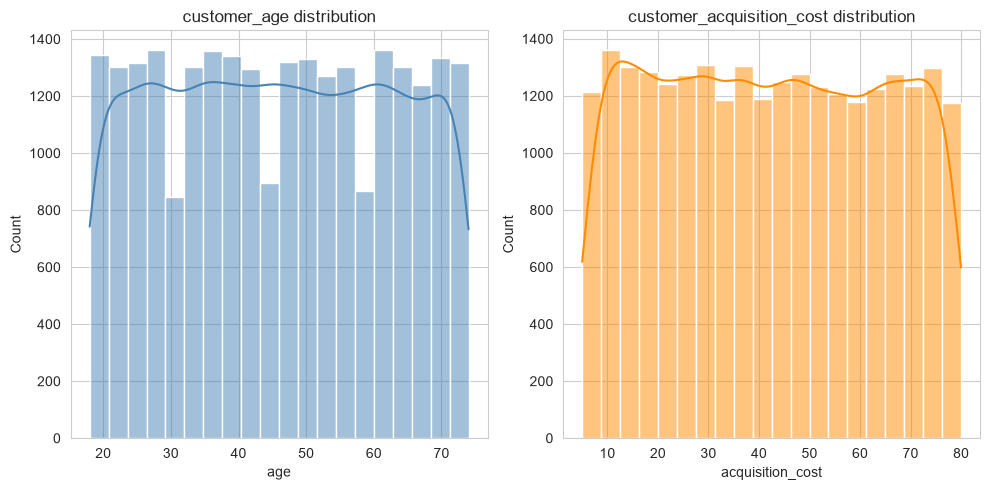

In [17]:
fig,axes=plt.subplots(1,2)
sns.histplot(df["customer_age"],bins=20,kde=True,ax=axes[0],color="steelblue")
axes[0].set_title("customer_age distribution")
axes[0].set_xlabel("age")

sns.histplot(df["customer_acquisition_cost"],bins=20,kde=True,ax=axes[1],color="darkorange")
axes[1].set_title("customer_acquisition_cost distribution")
axes[1].set_xlabel("acquisition_cost")

plt.tight_layout()
plt.show()

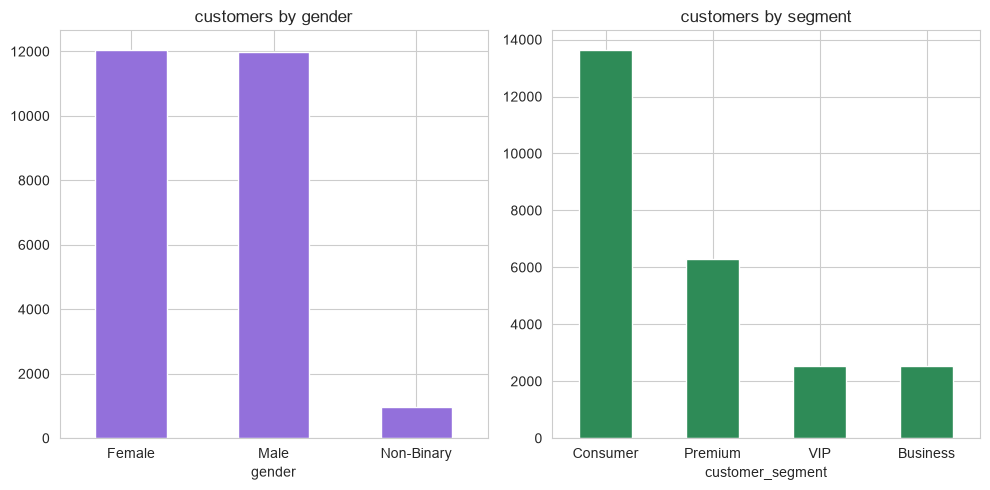

In [22]:
fig,axes=plt.subplots(1,2)

df["gender"].value_counts().plot(kind = "bar",ax=axes[0],color="mediumpurple")
axes[0].set_title("customers by gender")
axes[0].tick_params(axis="x",rotation=0)

df["customer_segment"].value_counts().plot(kind = "bar",ax=axes[1],color="seagreen")
axes[1].set_title("customers by segment")
axes[1].tick_params(axis="x",rotation=0)
plt.tight_layout()
plt.show()

In [25]:
unique_ids = df["customer_id"].is_unique
duplacte_rows=df.duplicated().sum()
duplacte_names=df["customer_name"].duplicated().sum()

In [26]:
pd.Series({
    "customer id is unique":unique_ids,
    "duplicate rows":duplacte_rows,
    "duplacte names":duplacte_names
})

customer id is unique    True
duplicate rows              0
duplacte names           3369
dtype: object

In [27]:
country_summary = df.groupby("customer_country").agg(
    customer_count=("customer_id","count"),
    avg_age =("customer_age","mean"),
    avg_acquistion_cost =("customer_acquisition_cost","mean") 
).sort_values("customer_count",ascending=False)

In [28]:
country_summary

,customer_count,avg_age,avg_acquistion_cost
customer_country,,,
USA,14925,45.928777,42.085881
UK,3701,45.883545,42.274712
Germany,2046,45.640762,42.217571
Canada,1279,46.275215,42.612651
Australia,1233,45.689376,42.972758
India,1041,46.024976,41.831585
UAE,775,45.909677,41.280594


Text(0.5, 0, 'Average acquistion cost')

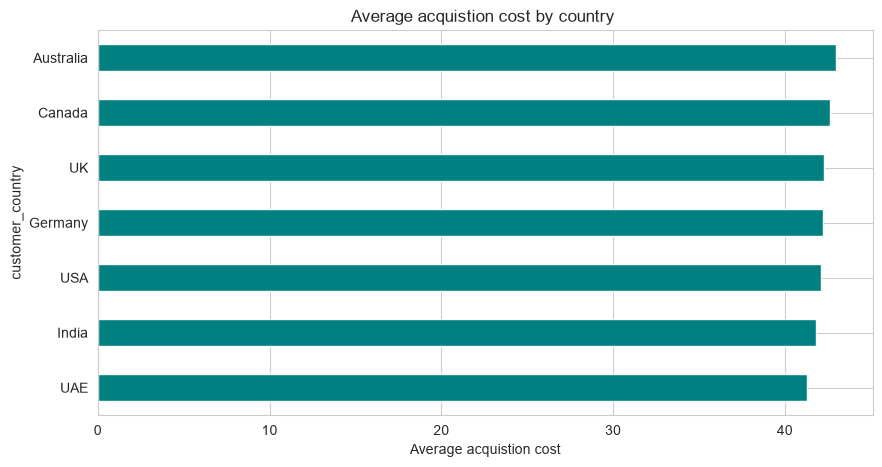

In [29]:
country_summary["avg_acquistion_cost"].sort_values().plot(kind="barh",color="teal")
plt.title("Average acquistion cost by country ")
plt.xlabel("Average acquistion cost")

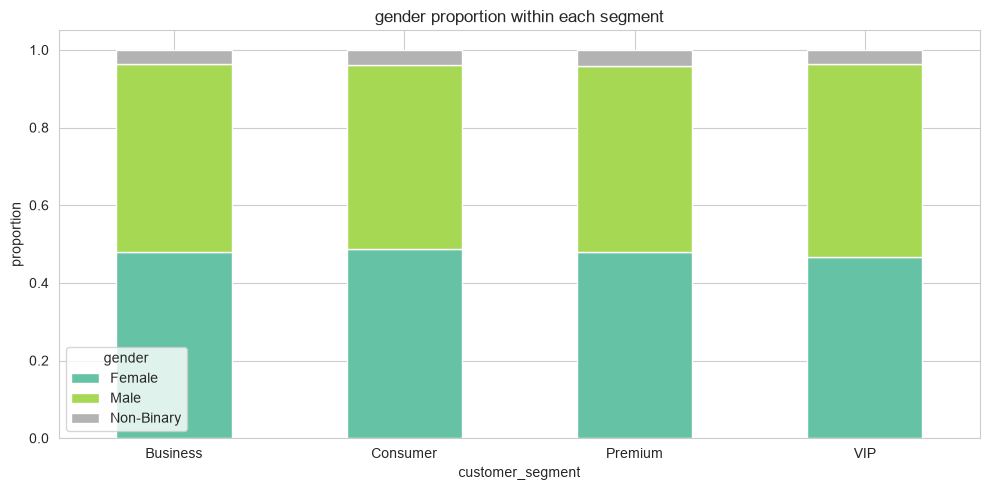

In [31]:
segment_gender = pd.crosstab(df["customer_segment"],df["gender"],normalize="index")
segment_gender.plot(kind="bar",stacked=True,colormap="Set2")
plt.title("gender proportion within each segment")
plt.xticks(rotation=0)
plt.ylabel("proportion")
plt.legend(title="gender")
plt.tight_layout()
plt.show()

In [33]:
pivot = df.pivot_table(
values="customer_acquisition_cost",
index="region",
columns="customer_segment",
aggfunc="mean"
)

In [34]:
pivot

customer_segment,Business,Consumer,Premium,VIP
region,,,,
Central,42.665208,42.381241,42.033338,40.903996
East,41.582421,41.498164,42.068956,43.113654
North,43.024669,42.521355,42.938065,39.870359
South,42.419132,42.260161,41.927955,42.680490
West,42.257776,42.587711,41.129324,42.167195


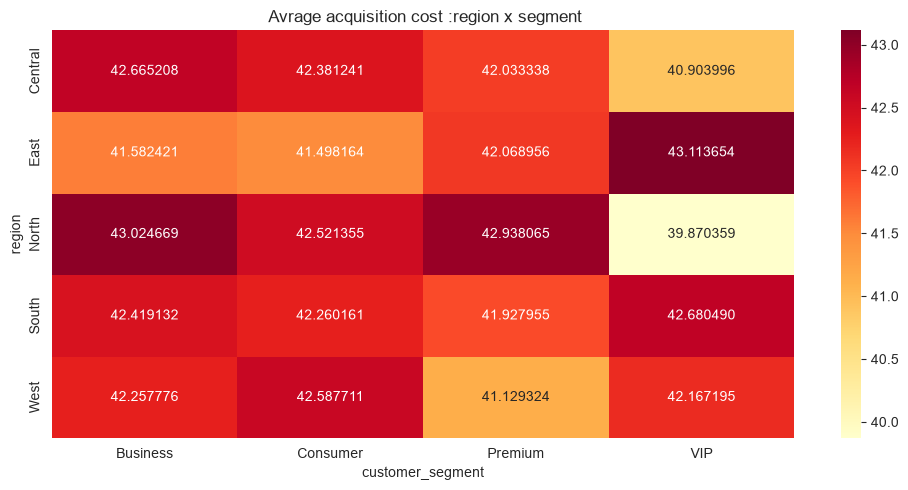

In [36]:
sns.heatmap(pivot,annot=True,fmt="1f",cmap="YlOrRd")
plt.title(" Avrage acquisition cost :region x segment")
plt.tight_layout()
plt.show()